## Homework - 22 Practice (Pandas & Matplotlib)

## Easy Questions

Q1. Load Dataset
Load ecommerce_practice_data.csv and display the first 10 rows.

In [3]:
import pandas as pd

ecommerce = pd.read_csv('ecommerce_practice_data.csv') 

ecommerce.head(10)

,Transaction_ID,Date,Customer_ID,Gender,Category,Product_Name,Unit_Price,Quantity,Payment_Method,Rating,Is_Returned,Shipping_Cost,Total_Amount
0,5001,2024-01-01,138,Female,Clothing,Product_1,240.27,3,Transfer,1,False,22.01,720.81
1,5002,2024-01-02,128,Female,Home,Product_2,146.98,4,Transfer,1,False,19.92,587.92
2,5003,2024-01-03,114,Male,Electronics,Product_3,442.91,1,Credit Card,5,False,13.17,442.91
3,5004,2024-01-04,142,Female,Beauty,Product_4,376.38,1,Credit Card,4,False,23.66,376.38
4,5005,2024-01-05,107,Male,Electronics,Product_5,477.01,5,PayPal,5,False,24.82,2385.05
5,5006,2024-01-06,120,Male,Electronics,Product_6,172.07,3,Transfer,4,False,9.10,516.21
6,5007,2024-01-07,138,Female,Home,Product_7,280.85,3,Credit Card,5,False,12.58,842.55
7,5008,2024-01-08,118,Female,Electronics,Product_8,290.42,5,Cash,5,True,23.53,1452.10
8,5009,2024-01-09,122,Male,Clothing,Product_9,490.36,4,Cash,3,False,19.43,1961.44
9,5010,2024-01-10,110,Male,Clothing,Product_10,46.92,3,Credit Card,5,False,5.96,140.76


Q2. Unique Customers
Using Customer_ID column, calculate total number of unique customers.

In [4]:
unique_customers = ecommerce["Customer_ID"].nunique()

print("Total unique customers:", unique_customers)

Total unique customers: 47


Q3. Total Revenue
Using Total_Amount column, calculate total revenue generated.

In [8]:
result = ecommerce['Total_Amount'].sum()

print("Total Revenue:", result)

Total Revenue: 88812.17


Q4. Average Rating
Using Rating column, calculate average customer rating.

In [10]:
result = ecommerce['Rating'].mean()

print("Average Rating:", result)

Average Rating: 2.933333333333333


Q5. Transactions by Category
Using Category column, count number of transactions for each category.

In [11]:
result = ecommerce.groupby('Category', as_index=False).agg(
    TransactionCount = ('Transaction_ID', 'count')
)

result

,Category,TransactionCount
0,Beauty,14
1,Books,28
2,Clothing,16
3,Electronics,32
4,Home,30


Q6. Payment Method Bar Chart
Using Payment_Method column, create a bar chart showing transaction frequency for each payment method.

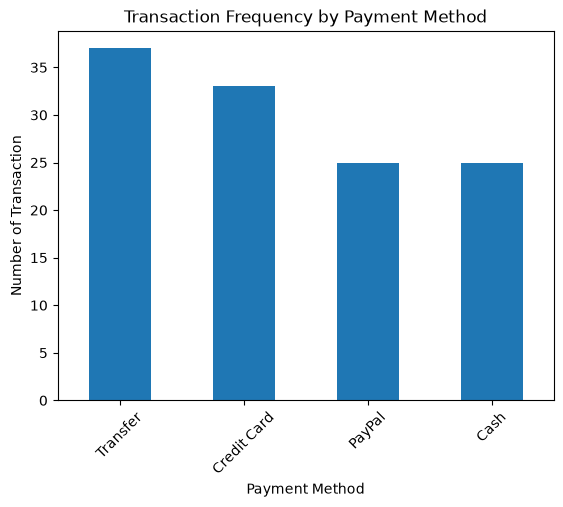

In [13]:
import matplotlib.pyplot as plt

payment_counts = ecommerce['Payment_Method'].value_counts()

# Bar chart
payment_counts.plot(kind='bar')

plt.title("Transaction Frequency by Payment Method")
plt.xlabel('Payment Method')
plt.ylabel("Number of Transaction")
plt.xticks(rotation=45)
plt.show()

Q7. High Amount Transactions
Filter transactions where Total_Amount > 400.

In [14]:
ecommerce[ecommerce['Total_Amount'] > 400]

,Transaction_ID,Date,Customer_ID,Gender,Category,Product_Name,Unit_Price,Quantity,Payment_Method,Rating,Is_Returned,Shipping_Cost,Total_Amount
0,5001,2024-01-01,138,Female,Clothing,Product_1,240.27,3,Transfer,1,False,22.01,720.81
1,5002,2024-01-02,128,Female,Home,Product_2,146.98,4,Transfer,1,False,19.92,587.92
2,5003,2024-01-03,114,Male,Electronics,Product_3,442.91,1,Credit Card,5,False,13.17,442.91
4,5005,2024-01-05,107,Male,Electronics,Product_5,477.01,5,PayPal,5,False,24.82,2385.05
5,5006,2024-01-06,120,Male,Electronics,Product_6,172.07,3,Transfer,4,False,9.10,516.21
...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,5116,2024-04-25,140,Male,Home,Product_116,472.68,2,Transfer,4,False,5.66,945.36
116,5117,2024-04-26,127,Female,Electronics,Product_117,434.93,5,Cash,4,False,23.25,2174.65
117,5118,2024-04-27,106,Female,Electronics,Product_118,321.84,5,PayPal,1,False,9.96,1609.20
118,5119,2024-04-28,108,Female,Books,Product_119,402.47,5,Cash,3,False,16.55,2012.35


Q8. Missing Values Check
Check the dataset for missing values using .isnull().sum(). Note: this dataset has no missing values — all results should return 0.

In [15]:
ecommerce.isnull().sum()

Transaction_ID    0
Date              0
Customer_ID       0
Gender            0
Category          0
Product_Name      0
Unit_Price        0
Quantity          0
Payment_Method    0
Rating            0
Is_Returned       0
Shipping_Cost     0
Total_Amount      0
dtype: int64

Q9. Unit Price Range
Using Unit_Price column, find minimum and maximum prices.

In [19]:
result = ecommerce['Unit_Price'].agg(
    MaxUnitPrice='max',
    MinUnitPrice='min'
)

result

MaxUnitPrice    491.10
MinUnitPrice     12.54
Name: Unit_Price, dtype: float64

Q10. Gender Distribution Pie Chart
Using Gender column, create a pie chart showing buyer gender distribution.

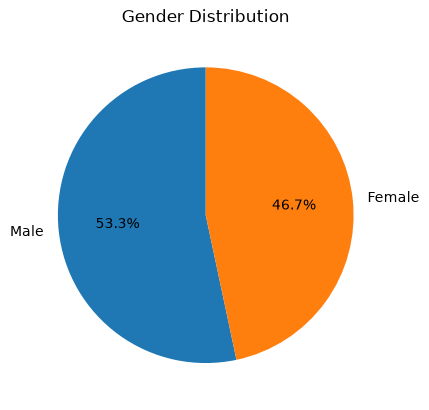

In [25]:
gender_counts = ecommerce['Gender'].value_counts()

plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Gender Distribution")
plt.show()

### Medium Questions

Q11. Average Price by Category
Using Category and Unit_Price columns, calculate average Unit_Price for each category.

In [29]:
result = ecommerce.groupby('Category', as_index=False).agg(
    UnitPriceCount = ('Unit_Price', 'mean')
)

result

,Category,UnitPriceCount
0,Beauty,247.295000
1,Books,208.067857
2,Clothing,245.502500
3,Electronics,245.238438
4,Home,256.768333


Q12. Sales Trend Line Chart
Using Date and Total_Amount columns, create a line chart showing Total_Amount trend over time.

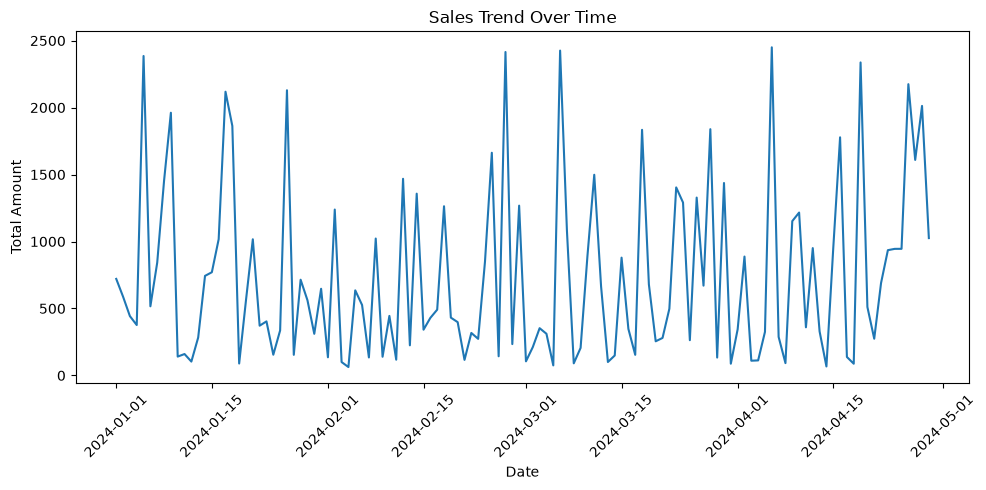

In [32]:
# Date ustunini datetime formatiga o'tkazish
ecommerce["Date"] = pd.to_datetime(ecommerce["Date"])

# Sana bo'yicha tartiblash
ecommerce = ecommerce.sort_values("Date")

# Line chart
plt.figure(figsize=(10, 5))
plt.plot(ecommerce["Date"], ecommerce["Total_Amount"])

plt.title("Sales Trend Over Time")
plt.xlabel("Date")
plt.ylabel("Total Amount")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Q13. Top Spending Customers
Using Customer_ID and Total_Amount columns, identify top 3 customers who spent the most money.

In [37]:
result = ecommerce.groupby('Customer_ID', as_index=False).agg(
    {'Total_Amount': 'sum'}
    ).sort_values(by='Total_Amount', ascending=False).head(3)

result

,Customer_ID,Total_Amount
1,101,5089.67
8,108,4609.41
42,144,4007.84


Q14. Final Price Calculation
Create a new column named Final_Price using:
Final_Price = Total_Amount + Shipping_Cost

In [38]:
ecommerce['Final_Price'] = ecommerce['Total_Amount'] + ecommerce['Shipping_Cost']

ecommerce

,Transaction_ID,Date,Customer_ID,Gender,Category,Product_Name,Unit_Price,Quantity,Payment_Method,Rating,Is_Returned,Shipping_Cost,Total_Amount,Final_Price
0,5001,2024-01-01,138,Female,Clothing,Product_1,240.27,3,Transfer,1,False,22.01,720.81,742.82
1,5002,2024-01-02,128,Female,Home,Product_2,146.98,4,Transfer,1,False,19.92,587.92,607.84
2,5003,2024-01-03,114,Male,Electronics,Product_3,442.91,1,Credit Card,5,False,13.17,442.91,456.08
3,5004,2024-01-04,142,Female,Beauty,Product_4,376.38,1,Credit Card,4,False,23.66,376.38,400.04
4,5005,2024-01-05,107,Male,Electronics,Product_5,477.01,5,PayPal,5,False,24.82,2385.05,2409.87
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,5116,2024-04-25,140,Male,Home,Product_116,472.68,2,Transfer,4,False,5.66,945.36,951.02
116,5117,2024-04-26,127,Female,Electronics,Product_117,434.93,5,Cash,4,False,23.25,2174.65,2197.90
117,5118,2024-04-27,106,Female,Electronics,Product_118,321.84,5,PayPal,1,False,9.96,1609.20,1619.16
118,5119,2024-04-28,108,Female,Books,Product_119,402.47,5,Cash,3,False,16.55,2012.35,2028.90


Q15. Unit Price Histogram
Using Unit_Price column, create a histogram showing price distribution.

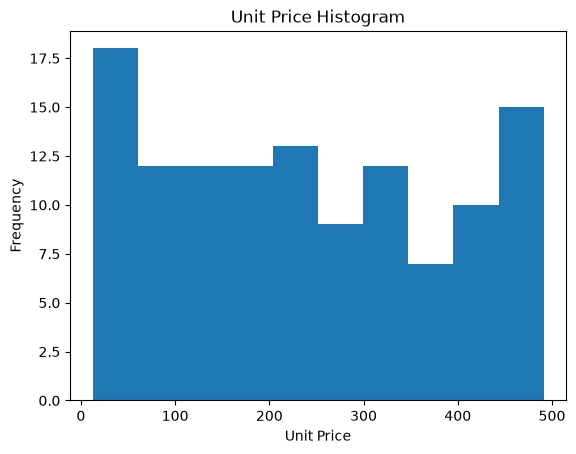

In [43]:
plt.hist(ecommerce["Unit_Price"], bins=10)

plt.title("Unit Price Histogram")
plt.xlabel("Unit Price")
plt.ylabel("Frequency")

plt.show()

Q16. Correlation Analysis
Using Quantity and Total_Amount columns, calculate correlation between both columns.

In [44]:
result = ecommerce["Quantity"].corr(ecommerce["Total_Amount"])

result

np.float64(0.579372973684668)

Q17. Electronics Return Analysis
Filter Category == 'Electronics' and calculate how many transactions were returned (Is_Returned == True).

In [63]:
result = ecommerce[
    (ecommerce["Category"] == "Electronics") &
    (ecommerce["Is_Returned"] == True)
].shape[0]

result

2

Q18. Category Box Plot
Using Category and Total_Amount columns, create a box plot comparing Total_Amount distributions.

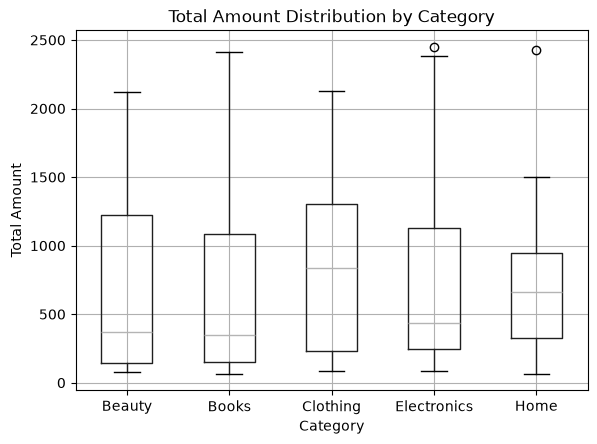

In [48]:
ecommerce.boxplot(column="Total_Amount", by="Category")

plt.title("Total Amount Distribution by Category")
plt.suptitle("")  
plt.xlabel("Category")
plt.ylabel("Total Amount")

plt.show()

Q19. February Transactions
Using Date column and .loc[], extract all transactions from February 2024. Hint: set Date as the DataFrame index first using df.set_index('Date') before using .loc['2024-02'].

In [51]:
ecommerce["Date"] = pd.to_datetime(ecommerce["Date"])
result = ecommerce.set_index('Date').loc['2024-02']

result

,Transaction_ID,Customer_ID,Gender,Category,Product_Name,Unit_Price,Quantity,Payment_Method,Rating,Is_Returned,Shipping_Cost,Total_Amount,Final_Price
Date,,,,,,,,,,,,,
2024-02-01,5032,141,Male,Beauty,Product_32,135.54,1,Transfer,5,False,15.64,135.54,151.18
2024-02-02,5033,127,Female,Home,Product_33,309.64,4,PayPal,1,True,6.33,1238.56,1244.89
2024-02-03,5034,115,Female,Books,Product_34,49.98,2,PayPal,2,False,9.58,99.96,109.54
2024-02-04,5035,114,Female,Books,Product_35,12.54,5,Transfer,1,False,15.86,62.70,78.56
2024-02-05,5036,146,Male,Home,Product_36,317.67,2,Transfer,3,False,13.63,635.34,648.97
2024-02-06,5037,143,Male,Books,Product_37,105.19,5,Transfer,1,False,11.66,525.95,537.61
2024-02-07,5038,102,Male,Home,Product_38,44.76,3,Credit Card,5,False,19.61,134.28,153.89
2024-02-08,5039,136,Female,Clothing,Product_39,204.42,5,Cash,4,True,18.87,1022.10,1040.97
2024-02-09,5040,106,Male,Home,Product_40,34.88,4,Credit Card,1,False,8.33,139.52,147.85


Q20. Scatter Plot
Using Unit_Price and Rating columns, create a scatter plot showing their relationship.

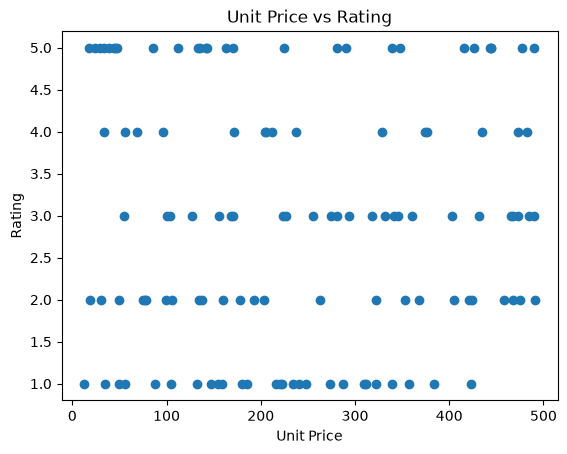

In [52]:
plt.scatter(ecommerce["Unit_Price"], ecommerce["Rating"])

plt.title("Unit Price vs Rating")
plt.xlabel("Unit Price")
plt.ylabel("Rating")

plt.show()

### Hard Questions

Q21. Business Performance Intelligence System — Using ecommerce_practice_data.csv, calculate category revenue, return rates, top customer spending, payment method popularity, and identify low-performing categories. Export business_performance.csv.

In [54]:
# 1. Category revenue
category_revenue = (
    ecommerce.groupby("Category", as_index=False)
    .agg(Category_Revenue=("Total_Amount", "sum"))
)

# 2. Return rates
return_rates = (
    ecommerce.groupby("Category", as_index=False)
    .agg(Return_Rate=("Is_Returned", "mean"))
)

# 3. Top customer spending
top_customer = (
    ecommerce.groupby("Customer_ID", as_index=False)
    .agg(Total_Spending=("Total_Amount", "sum"))
    .sort_values("Total_Spending", ascending=False)
)

print("Top Customer:")
print(top_customer.head())

# 4. Payment method popularity
payment_popularity = (
    ecommerce["Payment_Method"]
    .value_counts()
    .reset_index()
)

payment_popularity.columns = ["Payment_Method", "Transaction_Count"]

print("\nPayment Method Popularity:")
print(payment_popularity)

# 5. Business performance report
business_performance = (
    category_revenue.merge(return_rates, on="Category")
)

# O'rtacha revenue dan past bo'lgan kategoriyalarni aniqlash
average_revenue = business_performance["Category_Revenue"].mean()

business_performance["Low_Performing"] = (
    business_performance["Category_Revenue"] < average_revenue
)

# CSV ga eksport qilish
business_performance.to_csv("business_performance.csv", index=False)

print("\nBusiness Performance Report:")
print(business_performance)

Top Customer:
    Customer_ID  Total_Spending
1           101         5089.67
8           108         4609.41
42          144         4007.84
7           107         3988.14
36          138         3976.58

Payment Method Popularity:
  Payment_Method  Transaction_Count
0       Transfer                 37
1    Credit Card                 33
2         PayPal                 25
3           Cash                 25

Business Performance Report:
      Category  Category_Revenue  Return_Rate  Low_Performing
0       Beauty           9965.67     0.214286            True
1        Books          19752.28     0.107143           False
2     Clothing          13455.41     0.187500            True
3  Electronics          24443.04     0.062500           False
4         Home          21195.77     0.166667           False


Q22. Revenue Trend & Outlier Analytics — Using ecommerce_practice_data.csv, calculate cumulative revenue trends, detect transactions above the 95th percentile, compare monthly growth rates, identify revenue anomalies, and create trend visualizations.

Transactions Above 95th Percentile
     Transaction_ID       Date  Customer_ID  Gender     Category Product_Name  \
4              5005 2024-01-05          107    Male  Electronics    Product_5   
57             5058 2024-02-27          146    Male        Books   Product_58   
65             5066 2024-03-06          101    Male         Home   Product_66   
96             5097 2024-04-06          144    Male  Electronics   Product_97   
109            5110 2024-04-19          134  Female  Electronics  Product_110   
116            5117 2024-04-26          127  Female  Electronics  Product_117   

     Unit_Price  Quantity Payment_Method  Rating  Is_Returned  Shipping_Cost  \
4        477.01         5         PayPal       5        False          24.82   
57       482.97         5       Transfer       4        False          17.08   
65       485.07         5         PayPal       3        False          16.31   
96       489.96         5         PayPal       5        False           8.73 

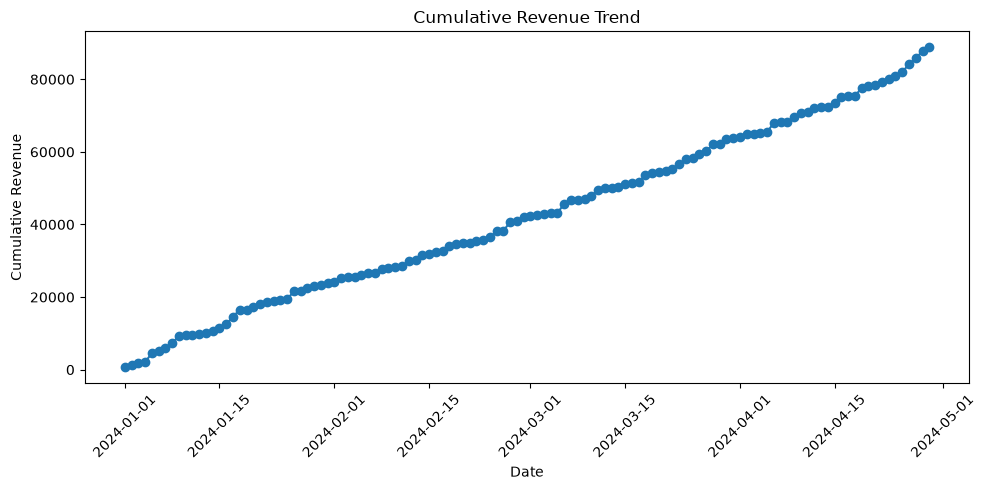

In [58]:
# Date ustunini datetime formatiga o'tkazish
ecommerce["Date"] = pd.to_datetime(ecommerce["Date"])

# Sana bo'yicha tartiblash
ecommerce = ecommerce.sort_values("Date")

# ====================================================
# 1. Cumulative Revenue Trend
# ====================================================

daily_revenue = (
    ecommerce.groupby("Date", as_index=False)
    .agg(Daily_Revenue=("Total_Amount", "sum"))
)

daily_revenue["Cumulative_Revenue"] = (
    daily_revenue["Daily_Revenue"].cumsum()
)

# ====================================================
# 2. Transactions above 95th percentile
# ====================================================

threshold = ecommerce["Total_Amount"].quantile(0.95)

high_transactions = ecommerce[
    ecommerce["Total_Amount"] > threshold
]

print("Transactions Above 95th Percentile")
print(high_transactions)

# ====================================================
# 3. Monthly Growth Rates
# ====================================================

ecommerce["Month"] = ecommerce["Date"].dt.to_period("M")

monthly_revenue = (
    ecommerce.groupby("Month", as_index=False)
    .agg(Monthly_Revenue=("Total_Amount", "sum"))
)

monthly_revenue["Growth_Rate"] = (
    monthly_revenue["Monthly_Revenue"].pct_change() * 100
)

print("\nMonthly Revenue")
print(monthly_revenue)

# ====================================================
# 4. Revenue Anomalies
# ====================================================

mean = ecommerce["Total_Amount"].mean()
std = ecommerce["Total_Amount"].std()

upper_limit = mean + 2 * std
lower_limit = mean - 2 * std

anomalies = ecommerce[
    (ecommerce["Total_Amount"] > upper_limit) |
    (ecommerce["Total_Amount"] < lower_limit)
]

print("\nRevenue Anomalies")
print(anomalies)

# ====================================================
# 5. Trend Visualization
# ====================================================

plt.figure(figsize=(10,5))

plt.plot(
    daily_revenue["Date"],
    daily_revenue["Cumulative_Revenue"],
    marker="o"
)

plt.title("Cumulative Revenue Trend")
plt.xlabel("Date")
plt.ylabel("Cumulative Revenue")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

Q23. Customer Segmentation Intelligence Engine — Using ecommerce_practice_data.csv, segment customers into VIP/Regular/Low groups using Total_Amount, calculate average rating per segment, detect high-value low-rating customers, and export customer_segmentation_report.csv.

In [59]:
# ===========================================
# 1. Customer spending
# ===========================================

customer_summary = (
    ecommerce.groupby("Customer_ID", as_index=False)
    .agg(
        Total_Spending=("Total_Amount", "sum"),
        Average_Rating=("Rating", "mean")
    )
)

# ===========================================
# 2. Customer Segmentation
# ===========================================

def segment(total):
    if total >= 1000:
        return "VIP"
    elif total >= 500:
        return "Regular"
    else:
        return "Low"

customer_summary["Segment"] = customer_summary["Total_Spending"].apply(segment)

# ===========================================
# 3. Average rating per segment
# ===========================================

segment_rating = (
    customer_summary.groupby("Segment", as_index=False)
    .agg(
        Average_Segment_Rating=("Average_Rating", "mean")
    )
)

print(segment_rating)

# ===========================================
# 4. High-value Low-rating customers
# ===========================================

high_value_low_rating = customer_summary[
    (customer_summary["Total_Spending"] >= 1000) &
    (customer_summary["Average_Rating"] < 3)
]

print(high_value_low_rating)

# ===========================================
# 5. Export report
# ===========================================

customer_summary.to_csv(
    "customer_segmentation_report.csv",
    index=False
)

print(customer_summary)

   Segment  Average_Segment_Rating
0      Low                2.666667
1  Regular                2.523810
2      VIP                2.980392
    Customer_ID  Total_Spending  Average_Rating Segment
1           101         5089.67        2.250000     VIP
6           106         3751.17        1.500000     VIP
14          115         1427.88        2.500000     VIP
20          121         2272.18        2.000000     VIP
21          122         3365.32        2.500000     VIP
22          123         3709.37        2.333333     VIP
26          127         3730.41        2.000000     VIP
27          128         1589.92        1.000000     VIP
28          129         1016.58        1.000000     VIP
29          130         1833.80        2.000000     VIP
32          134         3081.98        2.333333     VIP
37          139         2345.53        1.666667     VIP
39          141         1161.21        2.666667     VIP
    Customer_ID  Total_Spending  Average_Rating  Segment
0           100    

Q24. Return Rate by Category
Calculate return rate for each Category using:
(Number of returned transactions / Total transactions) * 100

In [61]:
# Return rate by category
result = (
    ecommerce.groupby("Category")
    .agg(
        Total_Transactions=("Is_Returned", "count"),
        Returned_Transactions=("Is_Returned", "sum")
    )
)

result["Return_Rate"] = (
    result["Returned_Transactions"]
    / result["Total_Transactions"]
    * 100
)

result

,Total_Transactions,Returned_Transactions,Return_Rate
Category,,,
Beauty,14,3,21.428571
Books,28,3,10.714286
Clothing,16,3,18.750000
Electronics,32,2,6.250000
Home,30,5,16.666667


Q25. Dual-Axis Business Analysis
Filter Home and Beauty categories into a new DataFrame.
Group by Date and calculate:

    - daily sales volume
    - average Rating

Then create a dual-axis chart visualizing both metrics.

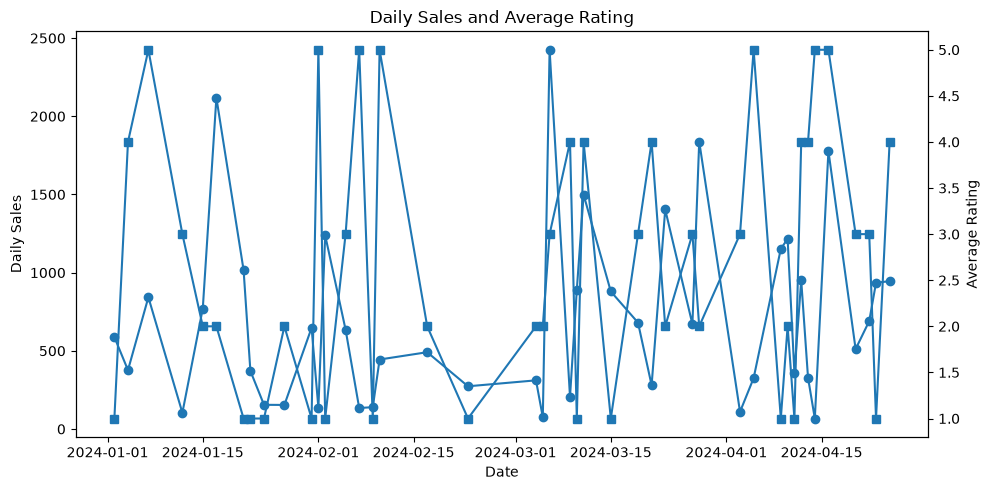

In [62]:
# Date ustunini datetime formatiga o'tkazish
ecommerce["Date"] = pd.to_datetime(ecommerce["Date"])

# Home va Beauty kategoriyalarini filtrlash
filtered = ecommerce[
    ecommerce["Category"].isin(["Home", "Beauty"])
]

# Sana bo'yicha guruhlash
daily_analysis = (
    filtered.groupby("Date", as_index=False)
    .agg(
        Daily_Sales=("Total_Amount", "sum"),
        Average_Rating=("Rating", "mean")
    )
)

# Dual-axis chart
fig, ax1 = plt.subplots(figsize=(10, 5))

# Birinchi o'q (Sales)
ax1.plot(
    daily_analysis["Date"],
    daily_analysis["Daily_Sales"],
    marker="o"
)

ax1.set_xlabel("Date")
ax1.set_ylabel("Daily Sales")

# Ikkinchi o'q (Rating)
ax2 = ax1.twinx()

ax2.plot(
    daily_analysis["Date"],
    daily_analysis["Average_Rating"],
    marker="s"
)

ax2.set_ylabel("Average Rating")

plt.title("Daily Sales and Average Rating")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()